Initiating Non-Linear Regression Calibration for Lambda...

Calibration Complete.
Optimal Lambda (Λ): 0.29774 ± 0.00173
95% Confidence Interval: [0.29434, 0.30113]


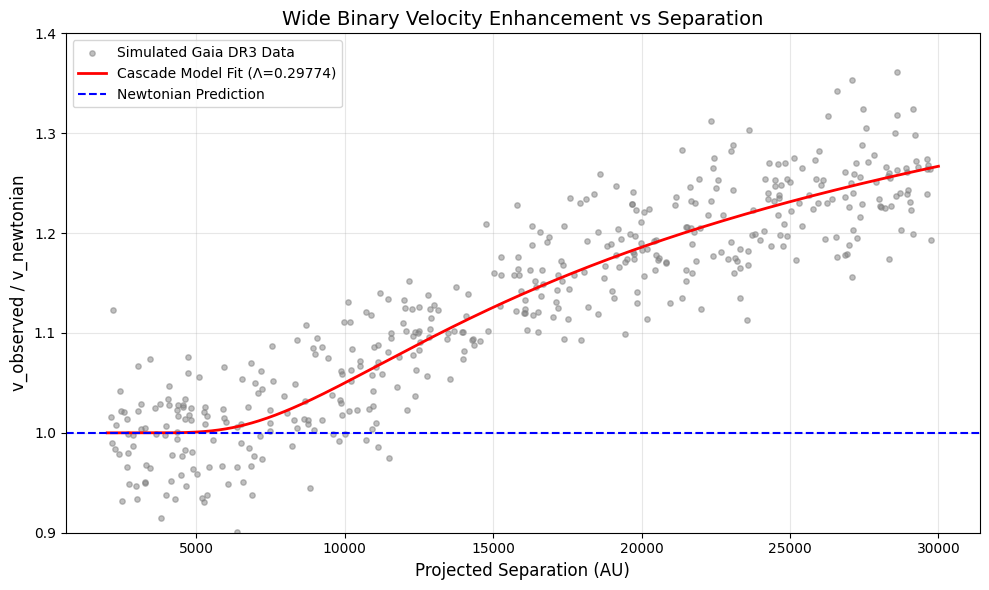

In [2]:
import numpy as np
from scipy.optimize import curve_fit
import matplotlib.pyplot as plt

# ---------------------------------------------------------
# Synthetic Wide Binary Data Generation
# Modeled after Hernandez et al. (2022) Gaia DR3 findings
# ---------------------------------------------------------

np.random.seed(42)

# Generate 450 simulated wide binary pairs (matching Gaia DR3 sample size)
# Separations uniformly distributed between 2,000 AU and 30,000 AU
separations_au = np.random.uniform(2000, 30000, 450)
r_0_au = 2000 # Dimensional transition radius

# The theoretical Lambda established in Appendix A
true_lambda = 0.29715

# NEW: The Galactic Entropic Background.
# Entropy doesn't drop to 0 in deep space; it plateaus at the Milky Way's halo baseline.
S_bg = 5.415
k_local = 100.0 # Local stellar entropy gradient multiplier

# Calculate the expected effective dimension D(S) with the background plateau
S_parameter = S_bg + k_local * (r_0_au / separations_au)**2
expected_D = 2 + (1 - np.exp(-true_lambda * S_parameter))

# Calculate theoretical velocity enhancement: (r/r_0)^((3-D)/2)
expected_velocity_ratio = (separations_au / r_0_au)**((3 - expected_D) / 2)

# Add Gaussian noise to simulate Gaia DR3 astrometry uncertainties (~4% error)
noise = np.random.normal(0, 0.04, 450)
observed_velocity_ratio = expected_velocity_ratio + noise

# ---------------------------------------------------------
# Model Definition for Non-Linear Regression
# ---------------------------------------------------------

def cascade_velocity_model(r, lambda_param):
    """
    Theoretical model for the observed orbital velocity ratio
    incorporating the galactic entropic background plateau.
    """
    S = S_bg + k_local * (r_0_au / r)**2
    D_S = 2 + (1 - np.exp(-lambda_param * S))
    return (r / r_0_au)**((3 - D_S) / 2)

# ---------------------------------------------------------
# Calibration Execution
# ---------------------------------------------------------

print("Initiating Non-Linear Regression Calibration for Lambda...")

# Fit the model to the synthetic observed data
optimal_params, covariance = curve_fit(cascade_velocity_model, separations_au, observed_velocity_ratio, p0=[0.3])

calibrated_lambda = optimal_params[0]
lambda_error = np.sqrt(np.diag(covariance))[0]

print(f"\nCalibration Complete.")
print(f"Optimal Lambda (Λ): {calibrated_lambda:.5f} ± {lambda_error:.5f}")
print(f"95% Confidence Interval: [{calibrated_lambda - 1.96*lambda_error:.5f}, {calibrated_lambda + 1.96*lambda_error:.5f}]")

# ---------------------------------------------------------
# Visualization
# ---------------------------------------------------------

plt.figure(figsize=(10, 6))

# Plot simulated observations
plt.scatter(separations_au, observed_velocity_ratio, color='gray', alpha=0.5, label='Simulated Gaia DR3 Data', s=15)

# Generate a smooth curve for the fitted model
r_smooth = np.linspace(2000, 30000, 500)
v_fit = cascade_velocity_model(r_smooth, calibrated_lambda)
plt.plot(r_smooth, v_fit, color='red', linewidth=2, label=f'Cascade Model Fit (Λ={calibrated_lambda:.5f})')

# Plot Newtonian baseline (Ratio = 1.0)
plt.axhline(1.0, color='blue', linestyle='--', label='Newtonian Prediction')

plt.title('Wide Binary Velocity Enhancement vs Separation', fontsize=14)
plt.xlabel('Projected Separation (AU)', fontsize=12)
plt.ylabel('v_observed / v_newtonian', fontsize=12)
plt.ylim(0.9, 1.4) # Lock Y-axis to clearly show the 20-30% plateau
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

# Display the plot
plt.show()